Feature Selection Results

Method: Forward Selection
Selected Features:
mean radius
mean perimeter
mean area
concavity error
fractal dimension error
worst radius
worst texture
worst perimeter
worst area
worst smoothness
Accuracy: 0.9772

Method: Backward Elimination
Selected Features:
mean concave points
concave points error
fractal dimension error
worst texture
worst perimeter
worst area
worst smoothness
worst concavity
worst symmetry
worst fractal dimension
Accuracy: 0.9824

Method: RFE
Selected Features:
mean concave points
radius error
area error
compactness error
worst radius
worst texture
worst perimeter
worst area
worst concavity
worst concave points
Accuracy: 0.9737

Method: LASSO
Selected Features:
worst radius
worst concave points
worst texture
mean concave points
radius error
worst smoothness
worst symmetry
worst concavity
worst compactness
worst fractal dimension
Accuracy: 0.9701

Method: Ridge
Selected Features:
worst texture
radius error
worst radius
area error
worst area

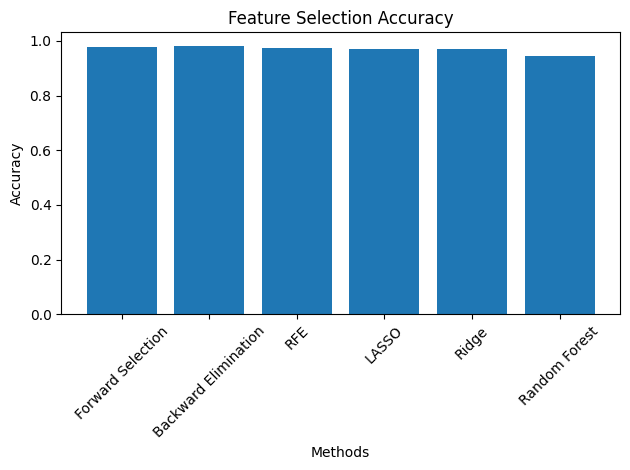

In [1]:

# Assignment 4 - Feature Selection
# Breast Cancer Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SequentialFeatureSelector, RFE
from sklearn.ensemble import RandomForestClassifier


# 1. Load Dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

feature_names = X.columns

N = 10

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# 2. Create Logistic Regression Model

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=10000))
])


# Function to calculate accuracy

def get_accuracy(features, classifier=model):

    scores = cross_val_score(
        classifier,
        X[features],
        y,
        cv=cv,
        scoring="accuracy"
    )

    return scores.mean()


# Store results

results = {}


# 3. Wrapper Methods

# Forward Selection

forward = SequentialFeatureSelector(
    model,
    n_features_to_select=N,
    direction="forward",
    cv=cv,
    scoring="accuracy"
)

forward.fit(X, y)

forward_features = list(feature_names[forward.get_support()])

results["Forward Selection"] = (
    forward_features,
    get_accuracy(forward_features)
)


# Backward Elimination

backward = SequentialFeatureSelector(
    model,
    n_features_to_select=N,
    direction="backward",
    cv=cv,
    scoring="accuracy"
)

backward.fit(X, y)

backward_features = list(feature_names[backward.get_support()])

results["Backward Elimination"] = (
    backward_features,
    get_accuracy(backward_features)
)


# RFE


rfe = RFE(
    model,
    n_features_to_select=N,
    importance_getter="named_steps.classifier.coef_"
)

rfe.fit(X, y)

rfe_features = list(feature_names[rfe.get_support()])

results["RFE"] = (
    rfe_features,
    get_accuracy(rfe_features)
)


# 4. Embedded Methods

# LASSO

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=0.1,
        max_iter=10000
    ))
])

lasso.fit(X, y)

lasso_coef = abs(lasso.named_steps["classifier"].coef_[0])

lasso_features = list(
    feature_names[np.argsort(lasso_coef)[-N:][::-1]]
)

results["LASSO"] = (
    lasso_features,
    get_accuracy(lasso_features)
)


# Ridge

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l2",
        solver="liblinear",
        C=1.0,
        max_iter=10000
    ))
])

ridge.fit(X, y)

ridge_coef = abs(ridge.named_steps["classifier"].coef_[0])

ridge_features = list(
    feature_names[np.argsort(ridge_coef)[-N:][::-1]]
)

results["Ridge"] = (
    ridge_features,
    get_accuracy(ridge_features)
)


# Random Forest

forest = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

forest.fit(X, y)

importance = forest.feature_importances_

forest_features = list(
    feature_names[np.argsort(importance)[-N:][::-1]]
)

results["Random Forest"] = (
    forest_features,
    get_accuracy(forest_features, forest)
)


# 5. Print Results

print("Feature Selection Results")

for method in results:

    features, accuracy = results[method]

    print("\nMethod:", method)

    print("Selected Features:")

    for feature in features:
        print(feature)

    print("Accuracy:", round(accuracy, 4))


# 6. Plot Accuracy Comparison

methods = list(results.keys())

accuracies = []

for method in methods:
    accuracies.append(results[method][1])

plt.bar(methods, accuracies)

plt.title("Feature Selection Accuracy")
plt.xlabel("Methods")
plt.ylabel("Accuracy")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()
